# Loan Default EDA

A quick look at the dataset, data quality, and features that may help predict loan default. `Status` is the target: **1 = default, 0 = non-default**.

In [12]:
import pandas as pd

df = pd.read_csv("Loan_Default.csv")  

print(df.shape)
print(df.dtypes)
df.head()

(148670, 34)
ID                             int64
year                           int64
loan_limit                    object
Gender                        object
approv_in_adv                 object
loan_type                     object
loan_purpose                  object
Credit_Worthiness             object
open_credit                   object
business_or_commercial        object
loan_amount                    int64
rate_of_interest             float64
Interest_rate_spread         float64
Upfront_charges              float64
term                         float64
Neg_ammortization             object
interest_only                 object
lump_sum_payment              object
property_value               float64
construction_type             object
occupancy_type                object
Secured_by                    object
total_units                   object
income                       float64
credit_type                   object
Credit_Score                   int64
co-applicant_credit_type 

,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


## 1. Load and inspect the data

The dataset has **148,670 rows and 34 columns**. The first few rows and data types help check that the file loaded correctly and show which columns are numeric or categorical.

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

sns.set_style("whitegrid")

def make_grid(n_plots, ncols=3, cell_w=5, cell_h=3.5):
    """Create a grid of axes sized for n_plots. Unused cells are hidden."""
    nrows = math.ceil(n_plots / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_w * ncols, cell_h * nrows))
    axes = axes.flatten() if n_plots > 1 else [axes]
    for ax in axes[n_plots:]:
        ax.set_visible(False)
    return fig, axes

## 2. Data quality checks

**Key findings**
- There are no duplicate rows or duplicate IDs.
- `year` has only one unique value, so it adds no useful variation.
- About **75.4%** of loans have `Status = 0` and **24.6%** have `Status = 1`. The target is imbalanced, but both classes have enough examples to evaluate.
- Missing values are highest in `Upfront_charges` (**26.7%**), `Interest_rate_spread` (**24.6%**) and `rate_of_interest` (**24.5%**).
- `LTV` reaches an implausible maximum of **7,831**, which needs checking before modelling.

In [14]:
# Missing values
miss = pd.DataFrame({
    "missing": df.isna().sum(),
    "pct": (df.isna().mean() * 100).round(2)
}).query("missing > 0").sort_values("pct", ascending=False)
print(miss)

# Duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())

# Constant columns and target balance
print("\nColumns with 1 unique value:", [c for c in df.columns if df[c].nunique() == 1])
print("\nTarget balance:")
print(df["Status"].value_counts(normalize=True).round(3))

# Quick sanity check on numeric ranges
print("\n", df.describe().T[["min", "max"]])

                           missing    pct
Upfront_charges              39642  26.66
Interest_rate_spread         36639  24.64
rate_of_interest             36439  24.51
dtir1                        24121  16.22
property_value               15098  10.16
LTV                          15098  10.16
income                        9150   6.15
loan_limit                    3344   2.25
approv_in_adv                  908   0.61
age                            200   0.13
submission_of_application      200   0.13
loan_purpose                   134   0.09
Neg_ammortization              121   0.08
term                            41   0.03

Duplicate rows: 0
Duplicate IDs: 0

Columns with 1 unique value: ['year']

Target balance:
Status
0    0.754
1    0.246
Name: proportion, dtype: float64

                                min           max
ID                    24890.000000  1.735590e+05
year                   2019.000000  2.019000e+03
loan_amount           16500.000000  3.576500e+06
rate_of_interest  

## 3. Check suspicious values and missingness

`ID` and `year` are removed because they are not useful predictors here. The checks also look at zero values, extreme LTV values, and whether missing data is associated with `Status`.

**Key findings**
- There is one zero value for `rate_of_interest`, **1,260** zero-income rows, and **17** rows with `LTV > 200`.
- Missingness in several columns is strongly associated with the target. For example, every row with missing `rate_of_interest` has `Status = 1` in this dataset.
- This pattern may be a data-collection or dataset artifact. It is a warning against using these columns or their missing-value patterns as predictors without checking when they would be available in a real prediction workflow.

In [15]:
# Drop useless columns
df = df.drop(columns=["ID", "year"])

# Count the suspicious zeros and extreme LTV
print("rate_of_interest == 0:", (df["rate_of_interest"] == 0).sum())
print("income == 0:", (df["income"] == 0).sum())
print("LTV > 200:", (df["LTV"] > 200).sum())
print(df["LTV"].describe(percentiles=[.01, .5, .99]).round(2))

# Does missingness relate to default?
cols = ["rate_of_interest", "Interest_rate_spread", "Upfront_charges", "dtir1", "LTV", "income"]
rows = {c: df.groupby(df[c].isna())["Status"].mean().round(3) for c in cols}
print("\nDefault rate when missing (True) vs present (False):")
print(pd.DataFrame(rows).T)

rate_of_interest == 0: 1
income == 0: 1260
LTV > 200: 17
count    133572.00
mean         72.75
std          39.97
min           0.97
1%           19.61
50%          75.14
99%         102.76
max        7831.25
Name: LTV, dtype: float64

Default rate when missing (True) vs present (False):
                      False  True 
rate_of_interest      0.002  1.000
Interest_rate_spread  0.000  1.000
Upfront_charges       0.001  0.920
dtir1                 0.163  0.676
LTV                   0.161  1.000
income                0.254  0.135


## 4. Clean suspicious values and explore distributions

Zero interest rates and zero incomes are treated as missing, and extreme `LTV` values above 200 are set to missing. The plots show the distributions of numeric columns and counts of categories.

**Key findings**
- Several numeric features are skewed, so their distributions are not perfectly symmetric.
- Some categorical columns are highly dominated by one category: `total_units` (98.5%), `lump_sum_payment` (97.7%) and `Credit_Worthiness` (95.7%), among others.
- Rare categories may have unstable default-rate estimates, so category-level results should be interpreted alongside their row counts.

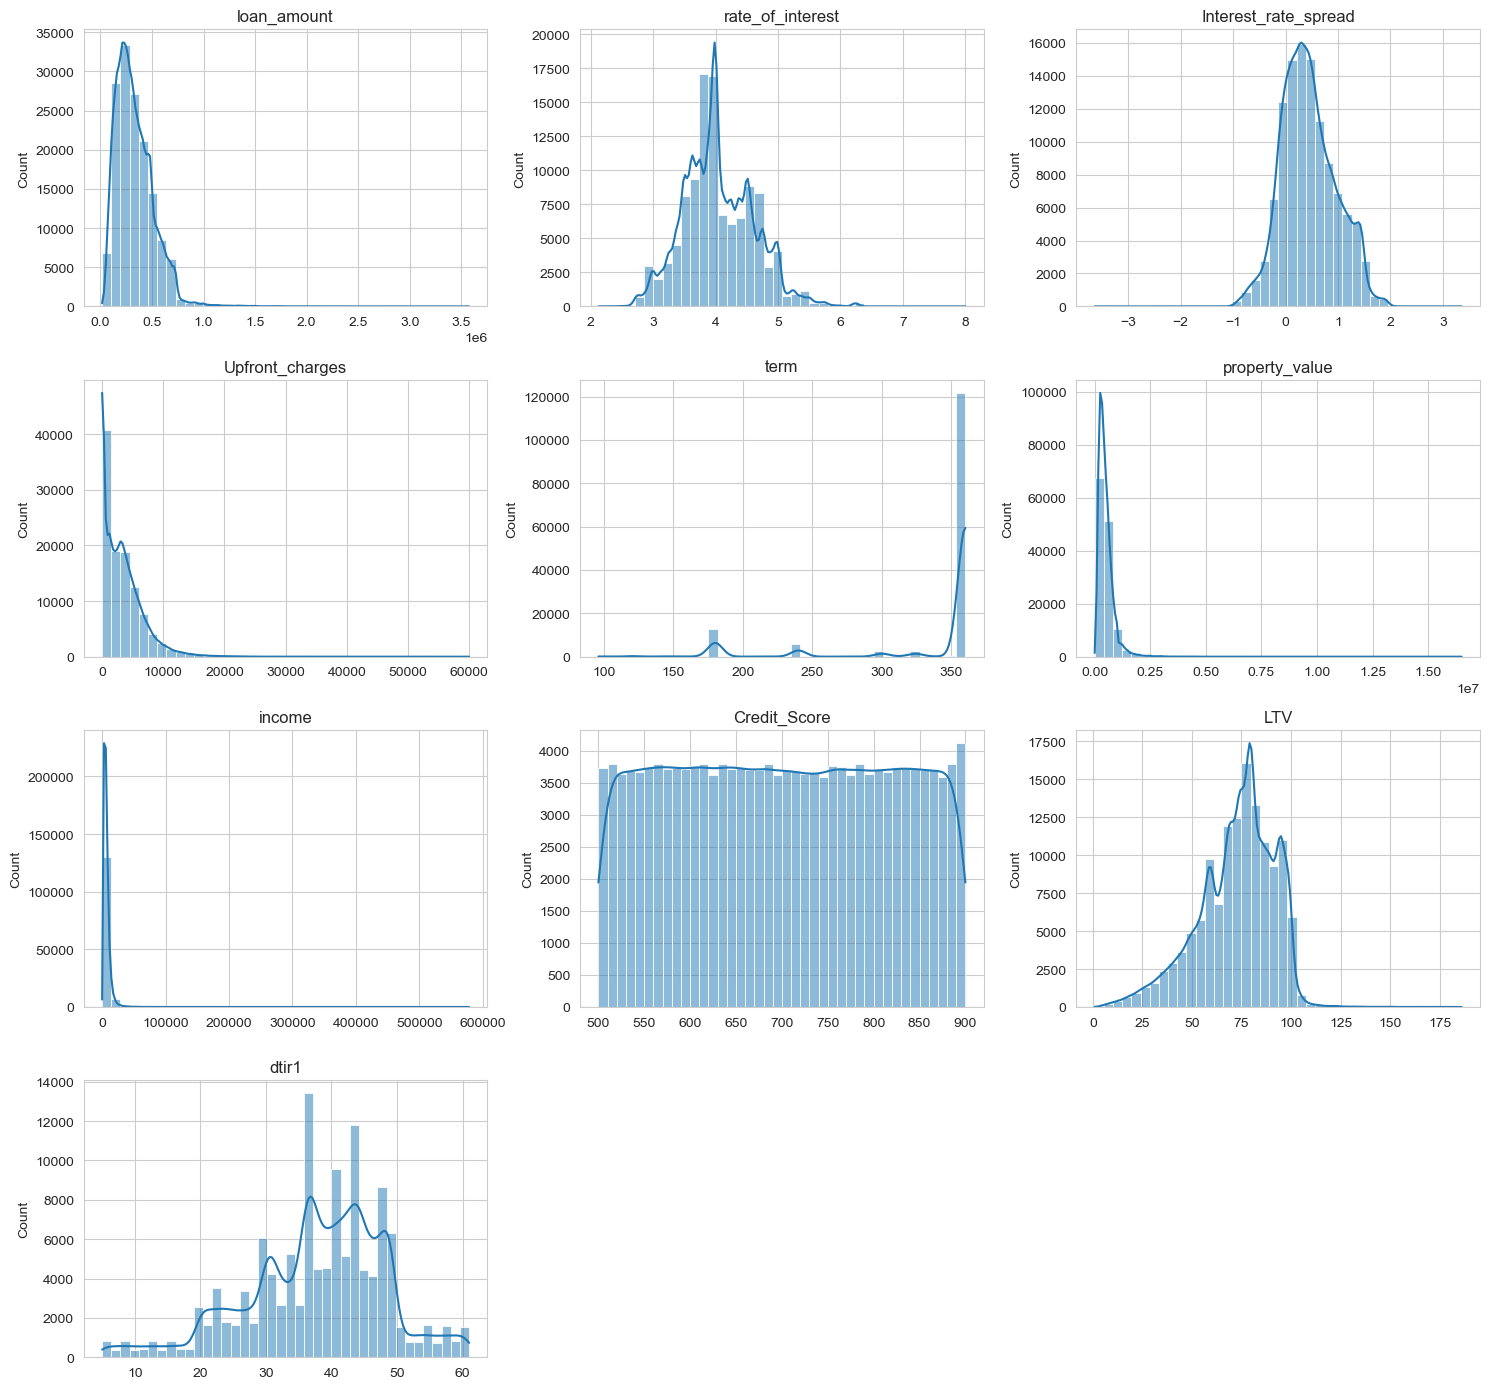

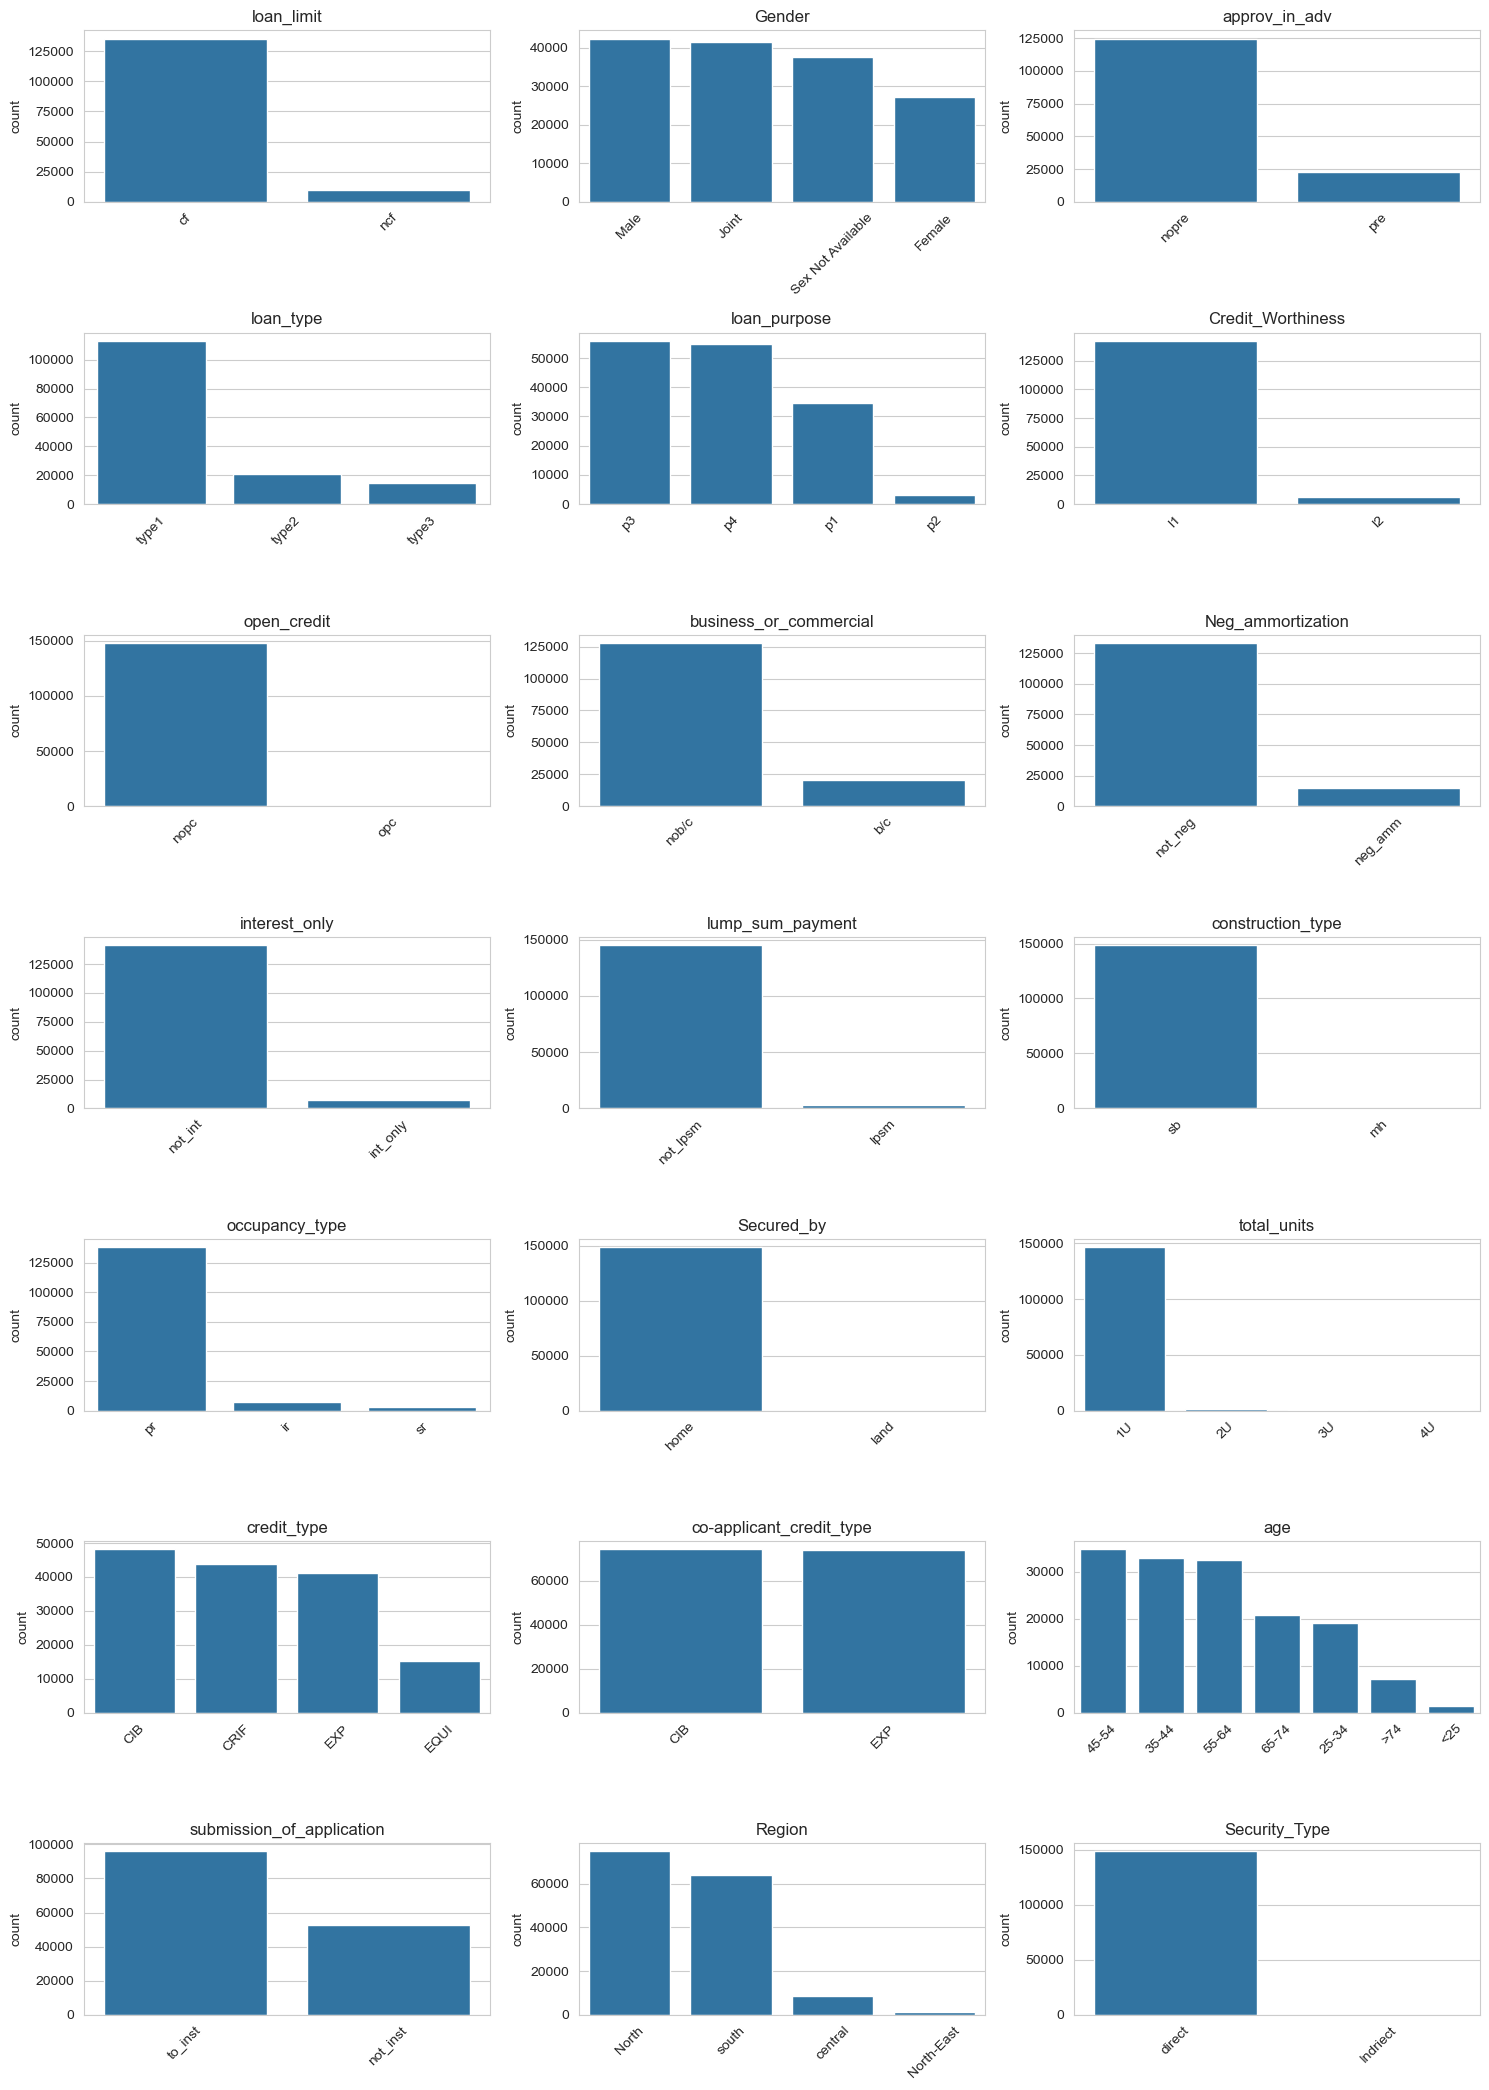

loan_limit: 93.1% of rows are one value
Credit_Worthiness: 95.7% of rows are one value
open_credit: 99.6% of rows are one value
interest_only: 95.2% of rows are one value
lump_sum_payment: 97.7% of rows are one value
construction_type: 100.0% of rows are one value
occupancy_type: 93.0% of rows are one value
Secured_by: 100.0% of rows are one value
total_units: 98.5% of rows are one value
Security_Type: 100.0% of rows are one value


In [16]:
import numpy as np

# Apply cleaning
df.loc[df["rate_of_interest"] == 0, "rate_of_interest"] = np.nan
df.loc[df["income"] == 0, "income"] = np.nan
df.loc[df["LTV"] > 200, "LTV"] = np.nan

# Figure 1: numeric distributions
num_cols = df.select_dtypes("number").columns.drop("Status")
fig, axes = make_grid(len(num_cols), ncols=3)
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c].dropna(), bins=40, ax=ax, kde=True)
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

# Figure 2: categorical counts
cat_cols = df.select_dtypes("object").columns
fig, axes = make_grid(len(cat_cols), ncols=3, cell_h=3)
for ax, c in zip(axes, cat_cols):
    order = df[c].value_counts().index
    sns.countplot(x=df[c], order=order, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Quick list of categorical columns with very dominant categories
for col in cat_cols:
    top_share = df[col].value_counts(normalize=True).max()
    if top_share > 0.9:
        print(f"{col}: {top_share:.1%} of rows are one value")

## 5. Compare features with loan status

The category charts compare each category's default rate with the overall rate. The boxplots compare numeric features for `Status = 0` and `Status = 1`, and the heatmap shows numeric correlations.

**What to look for**
- In the category charts, compare each bar with the dashed overall-default line; check the number of rows in each category before drawing conclusions.
- In boxplots, compare the medians and spread for the two status groups.
- Correlation shows linear association, not causation. Strong-looking patterns should be checked for leakage and data-quality issues before selecting features.

*Note: the plotting cell uses `overall_rate`; make sure it has been defined in the notebook session before running that cell.*

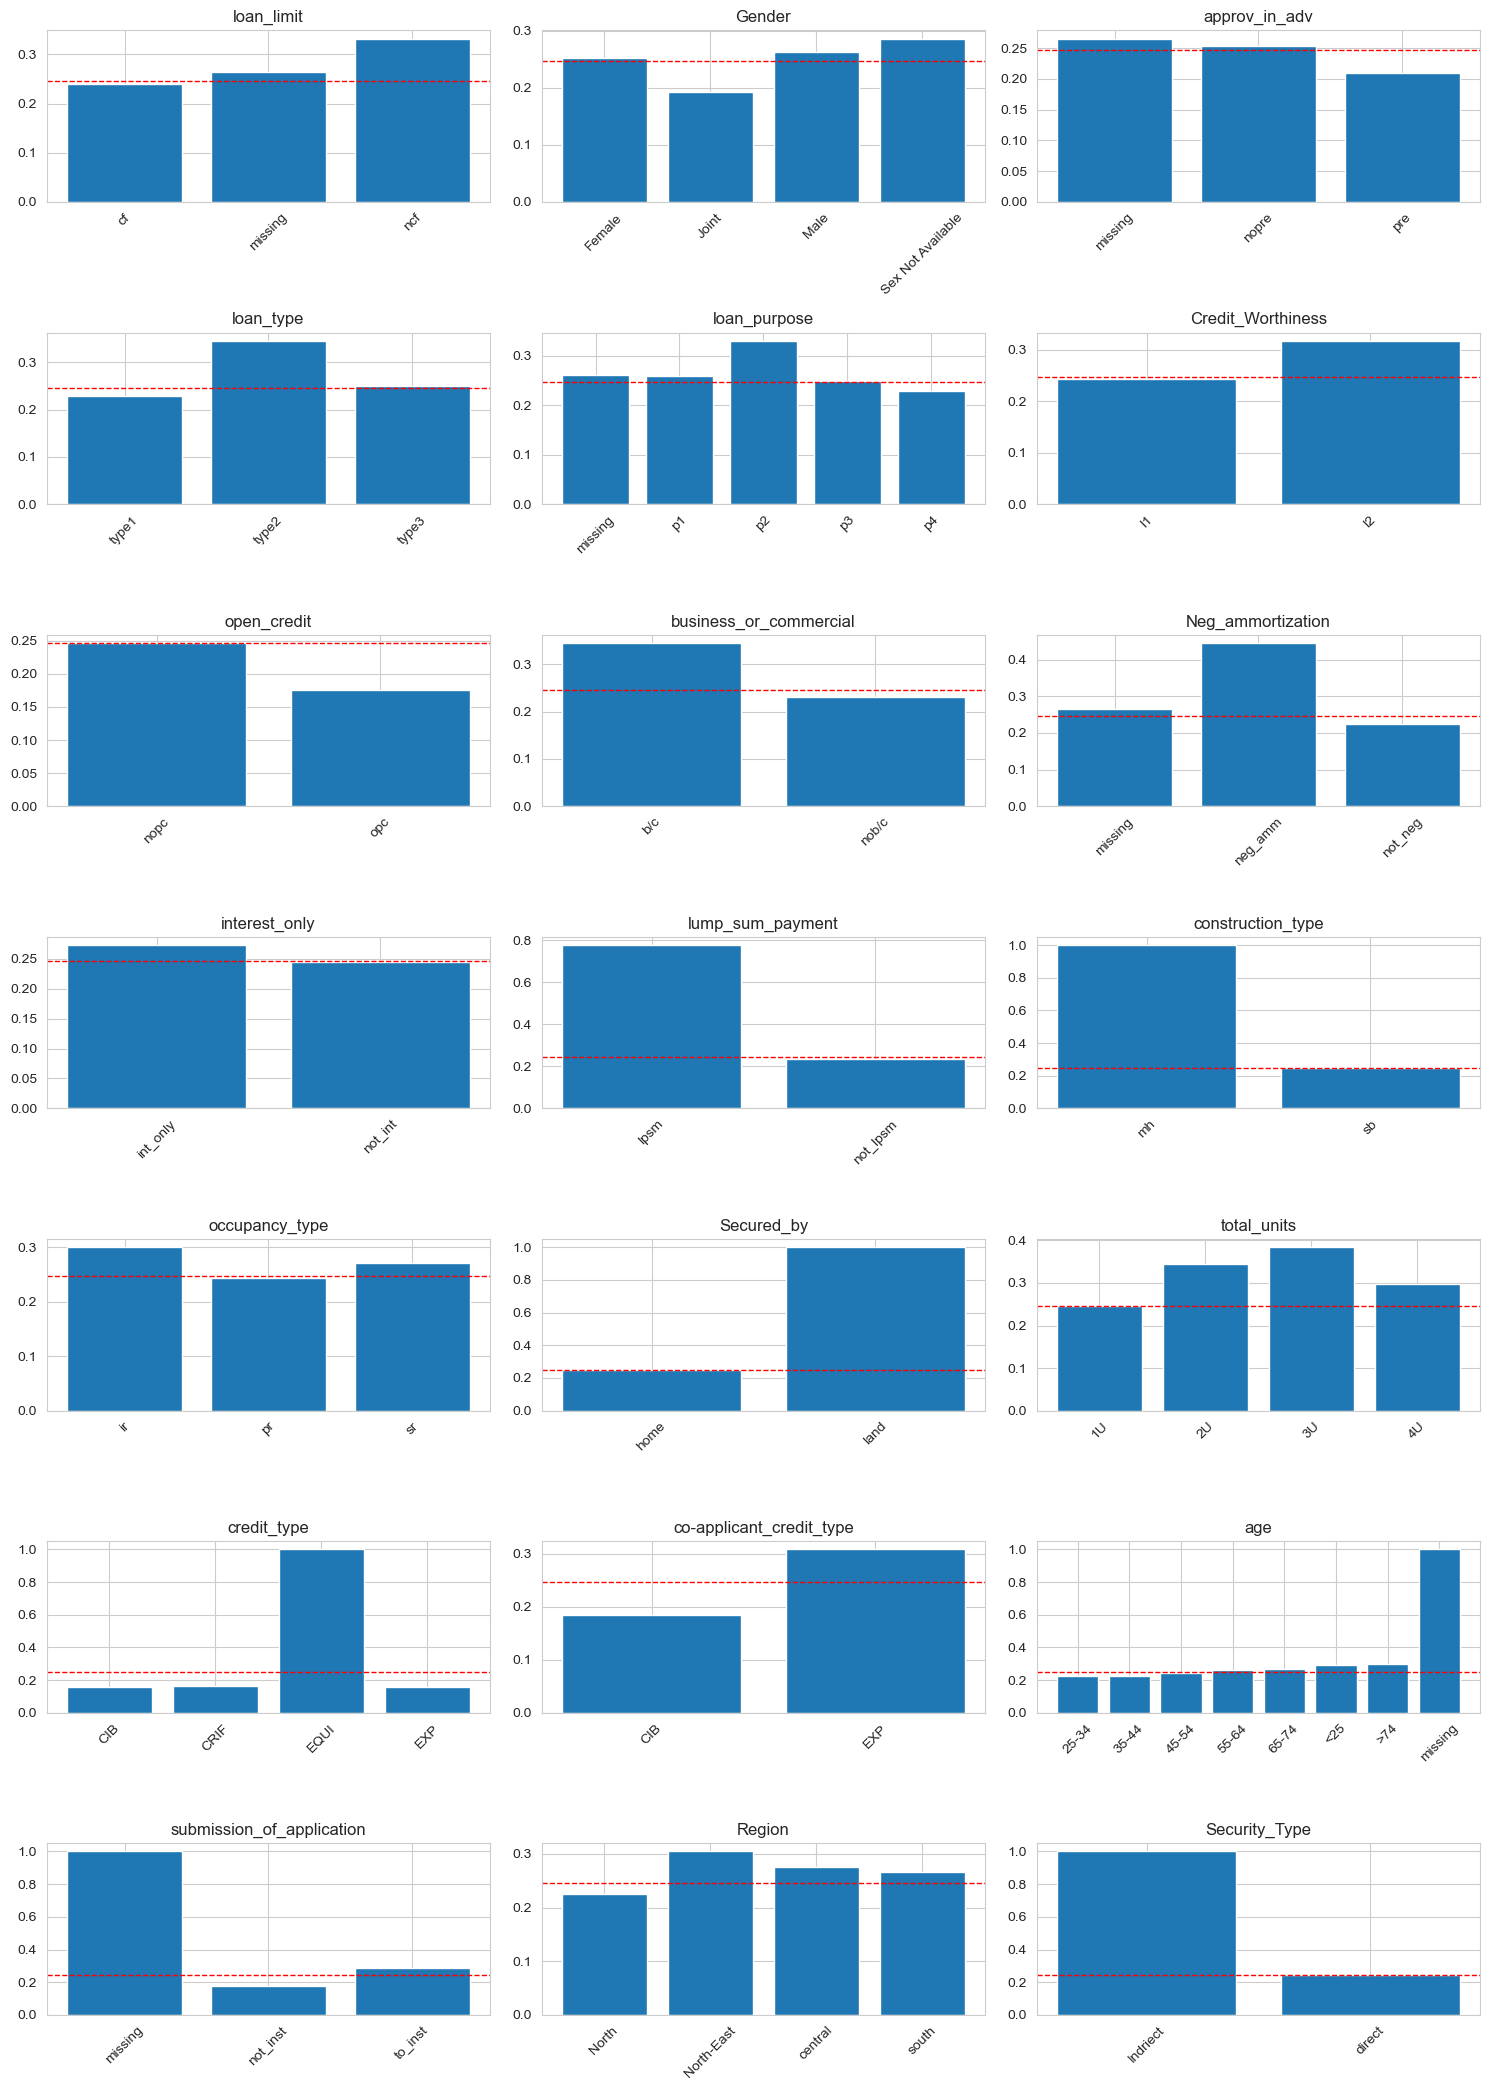

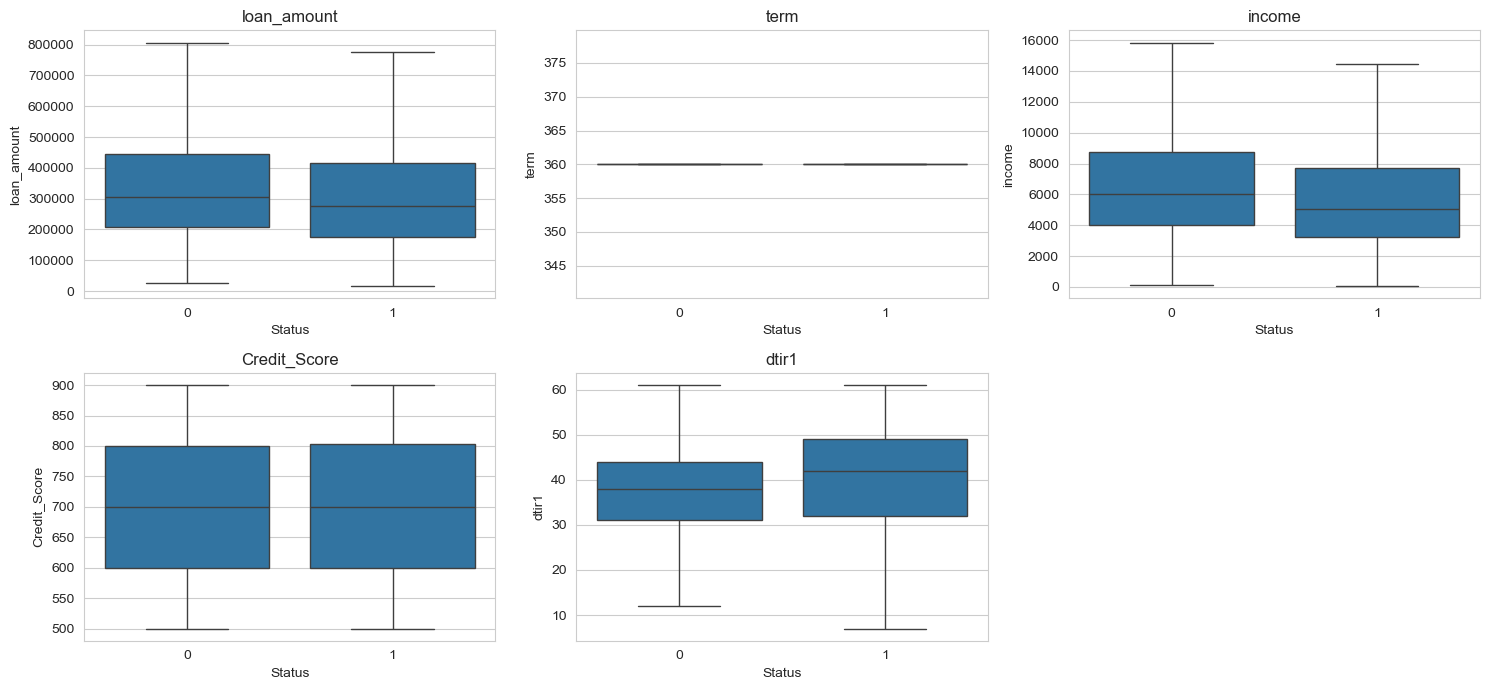

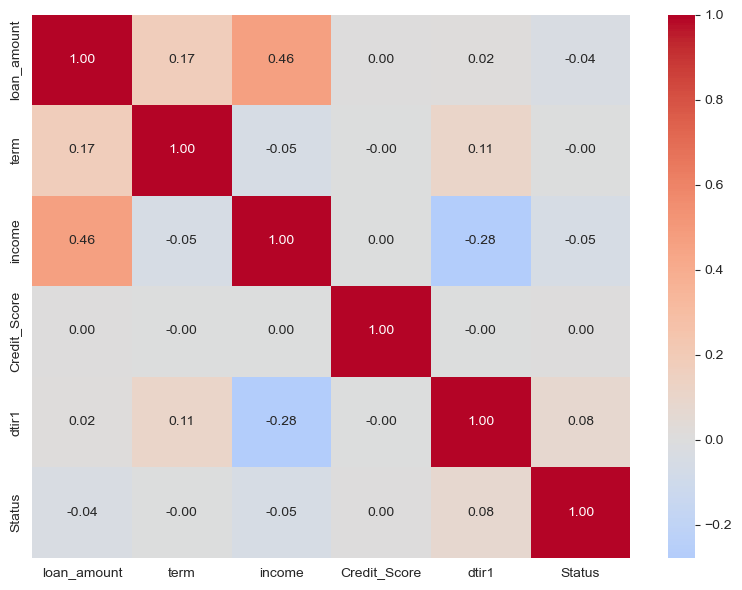

In [17]:
leak_cols = [
    "rate_of_interest",
    "Interest_rate_spread",
    "Upfront_charges",
    "LTV",
    "property_value",
]

cat_cols = df.select_dtypes("object").columns
num_cols = df.select_dtypes("number").columns.drop(["Status"] + leak_cols)
overall_rate = df["Status"].mean()

# Figure 1: default rate by category (red dashed line = overall rate)
fig, axes = make_grid(len(cat_cols), ncols=3, cell_h=3)

for ax, col in zip(axes, cat_cols):
    filled = df[col].fillna("missing")
    default_rate = df.groupby(filled)["Status"].mean()

    ax.bar(default_rate.index.astype(str), default_rate.values)
    ax.axhline(overall_rate, color="red", ls="--", lw=1)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


# Figure 2: numeric features split by target (0 vs 1)
fig, axes = make_grid(len(num_cols), ncols=3)

for ax, col in zip(axes, num_cols):
    sns.boxplot(x="Status", y=col, data=df, ax=ax, showfliers=False)
    ax.set_title(col)

plt.tight_layout()
plt.show()


# Figure 3: correlation heatmap
corr_cols = list(num_cols) + ["Status"]
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.tight_layout()
plt.show()

## 6. Check potentially useful categories

**Key findings**
- `lump_sum_payment = lpsm` has a much higher observed default rate (**77.7%**) than `not_lpsm` (**23.4%**), but the smaller group has only 3,384 rows.
- `Neg_ammortization = neg_amm` also has a higher observed default rate (**44.6%**) than `not_neg` (**22.4%**).
- The `EQUI` category in `credit_type` has a **100%** default rate, unlike the other categories. This looks suspicious and may be a dataset artifact, so it should not be treated as a reliable general pattern.
- Missing `age` and missing `submission_of_application` occur in exactly the same rows.
- Most loans have a 360-month term (**81.9%**). The high observed default rate for the 300-month group (**56.5%**) should be checked against its relatively small sample size.

In [18]:
check_cols = ["credit_type", "lump_sum_payment", "Neg_ammortization", "total_units"]

for col in check_cols:
    summary = df.groupby(col)["Status"].agg(rows="count", default_rate="mean")
    summary["default_rate"] = summary["default_rate"].round(3)
    print(summary, "\n")

# Are the two ~200-row missing groups the same rows?
same_rows = (df["age"].isna() == df["submission_of_application"].isna()).all()
print("age and submission_of_application missing together:", same_rows)

# How constant is term?
print(df["term"].value_counts(normalize=True).head(3).round(3))

              rows  default_rate
credit_type                     
CIB          48152         0.158
CRIF         43901         0.162
EQUI         15298         1.000
EXP          41319         0.160 

                    rows  default_rate
lump_sum_payment                      
lpsm                3384         0.777
not_lpsm          145286         0.234 

                     rows  default_rate
Neg_ammortization                      
neg_amm             15129         0.446
not_neg            133420         0.224 

               rows  default_rate
total_units                      
1U           146480         0.245
2U             1477         0.345
3U              393         0.384
4U              320         0.297 

age and submission_of_application missing together: True
term
360.0    0.819
180.0    0.087
240.0    0.039
Name: proportion, dtype: float64


## 7. Prepare a modelling dataset

The final cleaning step removes columns flagged as possible leakage, removes `credit_type` because of the suspicious `EQUI` pattern, and drops rows missing `age`.

**Key findings**
- The data changes from **148,670 rows and 28 columns** to **148,470 rows and 22 columns**.
- The default rate remains **24.5%** after this cleaning.
- Missing values remain in `dtir1` (**16.1%**) and `income` (**6.9%**), with smaller amounts in a few categorical columns. These will need an explicit imputation or missing-data strategy during preprocessing.
- This is a cleaned starting point, not yet a model-ready dataset. Fit preprocessing steps on the training data only, and check that every feature would be available at the time a real loan decision is made.

In [19]:
# Columns that leak the outcome (missingness predicts default)
leak_cols = [
    "rate_of_interest",
    "Interest_rate_spread",
    "Upfront_charges",
    "LTV",
    "property_value",
]

# Drop leak columns and credit_type (EQUI = 100% default artifact)
df_clean = df.drop(columns=leak_cols + ["credit_type"])

# Drop the ~200 rows where age and submission_of_application are missing
df_clean = df_clean.dropna(subset=["age"])

print("Shape before:", df.shape)
print("Shape after: ", df_clean.shape)
print(f"Default rate after cleaning: {df_clean['Status'].mean():.1%}")

# Remaining missing values
remaining_missing = df_clean.isna().mean().mul(100).round(1)
print("\nRemaining missing (%):")
print(remaining_missing[remaining_missing > 0].sort_values(ascending=False))

# Does term matter?
term_summary = df_clean.groupby("term")["Status"].agg(rows="count", default_rate="mean")
term_summary["default_rate"] = term_summary["default_rate"].round(3)
print("\nDefault rate by term:")
print(term_summary[term_summary["rows"] > 500])

Shape before: (148670, 32)
Shape after:  (148470, 26)
Default rate after cleaning: 24.5%

Remaining missing (%):
dtir1                16.1
income                6.9
loan_limit            2.2
approv_in_adv         0.6
loan_purpose          0.1
Neg_ammortization     0.1
dtype: float64

Default rate by term:
         rows  default_rate
term                       
120.0     510         0.182
180.0   12973         0.243
240.0    5853         0.207
300.0    2821         0.565
324.0    2661         0.225
360.0  121606         0.242


In [31]:
df_clean = df_clean.drop(columns = ['Secured_by', 'Security_Type'])

In [32]:
df_clean.columns

Index(['loan_limit', 'Gender', 'approv_in_adv', 'loan_type', 'loan_purpose',
       'Credit_Worthiness', 'open_credit', 'business_or_commercial',
       'loan_amount', 'term', 'Neg_ammortization', 'interest_only',
       'lump_sum_payment', 'construction_type', 'occupancy_type',
       'total_units', 'income', 'Credit_Score', 'co-applicant_credit_type',
       'age', 'submission_of_application', 'Region', 'Status', 'dtir1'],
      dtype='object')

Status,0,1
Security_Type,,
Indriect,0,33
direct,112031,36406
